# Purchase tracking and attribution audit

FormWise is a made-up online legal-document subscription service. The data is simulated (see `data/generate_data.py`).

**Why this started:** the marketing channel report, which joins front-end `purchase` events to users and channels,
showed mobile purchases dropping in spring 2026. Finance said revenue was steady. Which one is right, and what else
is the tracking getting wrong?

Plan:
1. Reconcile purchase events against billing records.
2. Find and size each data quality issue.
3. See how much channel credit changes under different attribution models.
4. Write a tracking plan and some automated checks.

In [1]:
import os, sys, sqlite3, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DB = "data/formwise.db"
if not os.path.exists(DB):
    subprocess.run([sys.executable, "data/generate_data.py"], check=True)
con = sqlite3.connect(DB)

def q(sql):
    if sql.endswith(".sql"):
        sql = open(sql).read()
    return pd.read_sql_query(sql, con)

BLUE, ORANGE, GREY = "#2B5C8A", "#D9822B", "#9AA5B1"
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
os.makedirs("figures", exist_ok=True)
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

## 1. Events vs billing, by week and platform

In [2]:
recon = q("""
WITH ev AS (
  SELECT strftime('%Y-%W', event_ts) AS week,
         CASE WHEN app_version = 'web' THEN 'web' ELSE 'mobile_app' END AS platform,
         COUNT(*) AS purchase_events,
         COUNT(user_id) AS attributable_events      -- events that can be joined to a user / channel
  FROM events WHERE event_name = 'purchase' GROUP BY week, platform
),
bill AS (
  SELECT strftime('%Y-%W', p.payment_ts) AS week,
         CASE WHEN v.device = 'mobile' THEN 'mobile_app' ELSE 'web' END AS platform,
         COUNT(*) AS billed_new_subs
  FROM payments p
  JOIN subscriptions s ON s.user_id = p.user_id
  JOIN visitors v ON v.visitor_id = s.visitor_id
  WHERE p.payment_type = 'new' GROUP BY week, platform
)
SELECT b.week, b.platform, b.billed_new_subs,
       COALESCE(e.purchase_events, 0) AS purchase_events,
       COALESCE(e.attributable_events, 0) AS attributable_events
FROM bill b LEFT JOIN ev e ON e.week = b.week AND e.platform = b.platform
ORDER BY b.week, b.platform
""")
recon["events_vs_billing"] = recon.attributable_events / recon.billed_new_subs - 1
print(recon.groupby("platform")[["billed_new_subs", "purchase_events", "attributable_events"]].sum().to_string())

            billed_new_subs  purchase_events  attributable_events
platform                                                         
mobile_app             1888             1925                 1787
web                    6695             6673                 6673


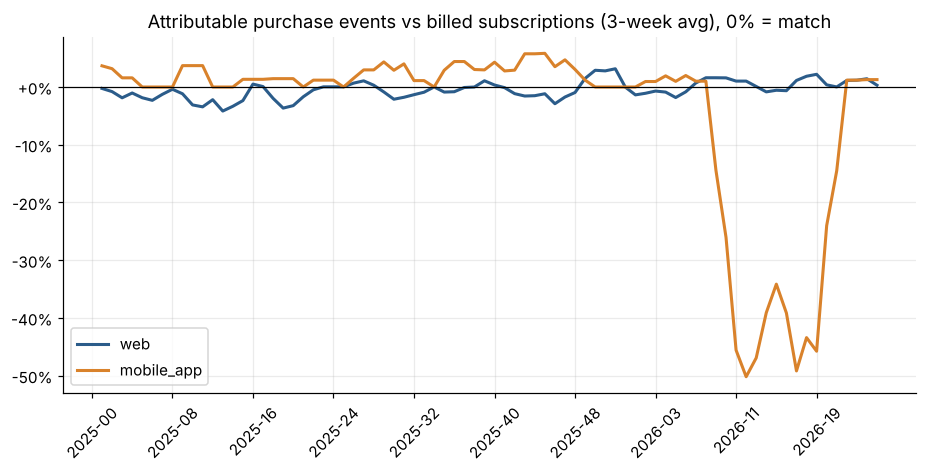

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for plat, col in [("web", BLUE), ("mobile_app", ORANGE)]:
    r = recon[recon.platform == plat]
    ax.plot(r.week, r.events_vs_billing.rolling(3, center=True).mean(), color=col, lw=2, label=plat)
ax.axhline(0, color="black", lw=0.8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ticks = recon.week.unique()[::8]; ax.set_xticks(ticks, ticks, rotation=45)
ax.set_title("Attributable purchase events vs billed subscriptions (3-week avg), 0% = match")
ax.legend(); fig.savefig("figures/reconciliation.png", bbox_inches="tight", dpi=140); plt.show()

Mobile matches billing closely except for a big dip in spring 2026, which is what the channel report picked up.
Web looks almost perfect, but as section 2 shows, that's two errors cancelling out: duplicates push the count up
and missing events push it down. A total that matches doesn't mean the tracking is right.

## 2. The issues, one at a time

In [4]:
dq = q("""
SELECT app_version,
       COUNT(*)                                                AS purchase_events,
       SUM(user_id IS NULL)                                    AS missing_user_id,
       ROUND(1.0 * SUM(user_id IS NULL) / COUNT(*), 4)         AS missing_user_id_rate,
       COUNT(*) - COUNT(DISTINCT COALESCE(order_id, event_id)) AS duplicate_order_events
FROM events WHERE event_name = 'purchase'
GROUP BY app_version ORDER BY app_version
""")
print(dq.to_string(index=False))

app_version  purchase_events  missing_user_id  missing_user_id_rate  duplicate_order_events
      3.1.4             1448                0                0.0000                      29
      3.2.0              313              138                0.4409                       5
      3.2.1              164                0                0.0000                       2
        web             6673                0                0.0000                     169


In [5]:
dups = q("""
SELECT order_id, COUNT(*) AS n,
       (julianday(MAX(event_ts)) - julianday(MIN(event_ts))) * 86400 AS seconds_apart
FROM events WHERE event_name = 'purchase' AND order_id IS NOT NULL
GROUP BY order_id HAVING COUNT(*) > 1
""")
missing = q("""
SELECT COUNT(*) AS n FROM subscriptions s
JOIN visitors v ON v.visitor_id = s.visitor_id
WHERE v.device <> 'mobile'
  AND NOT EXISTS (SELECT 1 FROM events e WHERE e.event_name = 'purchase' AND e.visitor_id = s.visitor_id)
""").n[0]
web_billed = recon[recon.platform == "web"].billed_new_subs.sum()
bug = dq.set_index("app_version").loc["3.2.0"]
issues = pd.DataFrame([
    ["Duplicate purchase events", f"{len(dups):,} orders sent twice, median {dups.seconds_apart.median():.0f}s apart",
     "Inflates conversion", "Dedupe on order_id"],
    ["Missing user_id / order_id", f"{bug.missing_user_id_rate:.0%} of app 3.2.0 purchase events",
     "Purchases can't be tied to users, channels or tests", "Fixed in 3.2.1; add a required-field check to release QA"],
    ["Purchase event never sent", f"{missing:,} web orders ({missing/web_billed:.1%})",
     "Ad blockers, or tab closed before confirmation page", "Send purchase server-side from the billing webhook"],
], columns=["issue", "size", "impact", "fix"])
print(issues.to_string(index=False))

                     issue                                   size                                              impact                                                      fix
 Duplicate purchase events 205 orders sent twice, median 3s apart                                 Inflates conversion                                       Dedupe on order_id
Missing user_id / order_id       44% of app 3.2.0 purchase events Purchases can't be tied to users, channels or tests Fixed in 3.2.1; add a required-field check to release QA
 Purchase event never sent                  191 web orders (2.9%) Ad blockers, or tab closed before confirmation page       Send purchase server-side from the billing webhook


In [6]:
w = q("""
SELECT
  (SELECT COUNT(*) FROM events WHERE event_name='purchase' AND app_version='3.2.0' AND user_id IS NOT NULL) AS ok,
  (SELECT COUNT(*) FROM events WHERE event_name='purchase' AND app_version='3.2.0') AS total
""")
print(f"Mobile purchases usable in user-level reports during 3.2.0: {w.ok[0]:,} of {w.total[0]:,} ({w.ok[0]/w.total[0]:.0%})")

Mobile purchases usable in user-level reports during 3.2.0: 175 of 313 (56%)


For the 11 weeks app 3.2.0 was live, any report joining purchases to users, channels or experiments undercounted
mobile by that much. That window overlapped the paywall A/B test, which is why that test was analysed on billing
data instead.

## 3. Attribution: who gets credit for a sale?
Each buyer had 1 to 4 marketing touches before their first visit. I compared last touch (what the current report
uses), first touch, linear, and position-based (40% first, 40% last, 20% split across the middle).

In [7]:
touches = q("""
SELECT t.visitor_id, t.channel, t.touch_ts, p.amount
FROM marketing_touches t
JOIN subscriptions s ON s.visitor_id = t.visitor_id
JOIN payments p ON p.user_id = s.user_id AND p.payment_type = 'new'
ORDER BY t.visitor_id, t.touch_ts
""")
touches["pos"] = touches.groupby("visitor_id").cumcount()
touches["n"] = touches.groupby("visitor_id").visitor_id.transform("size")

def weights(model, pos, n):
    if model == "last_touch": return (pos == n - 1).astype(float)
    if model == "first_touch": return (pos == 0).astype(float)
    if model == "linear": return 1.0 / n
    return np.where(n == 1, 1.0, np.where(n == 2, 0.5, np.where((pos == 0) | (pos == n - 1), 0.4, 0.2 / (n - 2).clip(lower=1))))

credit = pd.DataFrame({m: (touches.amount * weights(m, touches.pos, touches.n)).groupby(touches.channel).sum()
                       for m in ["last_touch", "first_touch", "linear", "position_based"]})
share = credit / credit.sum()
share["change_vs_last_touch"] = share.position_based - share.last_touch
print((share * 100).round(1).sort_values("change_vs_last_touch").to_string())
print("\nTotal credited by each model:", credit.sum().round(0).unique())

                last_touch  first_touch  linear  position_based  change_vs_last_touch
channel                                                                              
organic_search        36.7         31.0    33.3            33.5                  -3.2
direct                14.8          9.5    11.6            11.9                  -2.9
paid_search           27.4         23.4    25.2            25.3                  -2.1
email                  9.2          9.8     9.6             9.5                   0.4
referral               4.5          6.3     5.6             5.5                   1.0
social                 7.3         20.1    14.8            14.3                   6.9

Total credited by each model: [529180.]


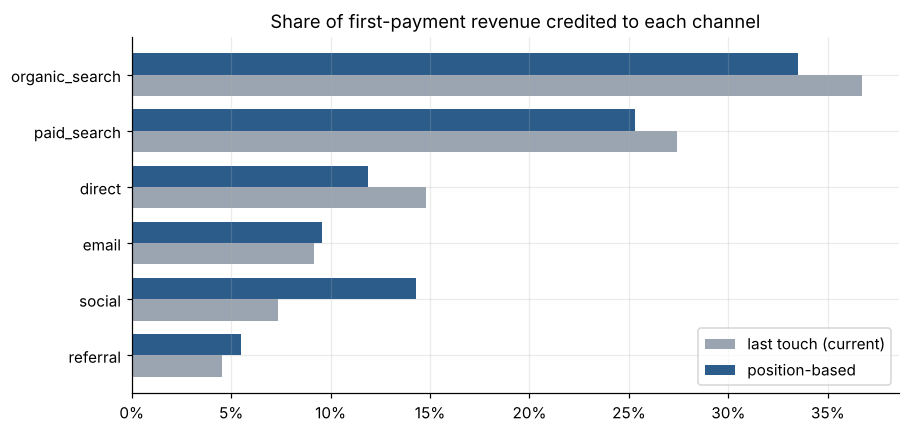

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.2))
sh = share.sort_values("last_touch")
y = np.arange(len(sh)); h = 0.38
ax.barh(y - h/2, sh.last_touch, h, color=GREY, label="last touch (current)")
ax.barh(y + h/2, sh.position_based, h, color=BLUE, label="position-based")
ax.set_yticks(y, sh.index); ax.xaxis.set_major_formatter(pct); ax.legend()
ax.set_title("Share of first-payment revenue credited to each channel")
fig.savefig("figures/attribution.png", bbox_inches="tight", dpi=140); plt.show()

Social is the channel last-touch undervalues most. It often starts the journey, then the sale comes through search
or a direct visit, and last touch gives search all the credit. If budget follows last-touch numbers, social will
keep getting cut. No attribution model is "the truth", so I'd show last touch and position-based side by side, and
run a holdout (pause social in a few regions) before moving money.

## 4. Tracking plan and daily checks

In [9]:
plan = pd.DataFrame([
    ["template_start", "visitor_id, doc_type, device, app_version", "Once per visitor per template"],
    ["form_field_error (new)", "visitor_id, doc_type, field_name, error_type", "Shows where mobile forms fail"],
    ["form_abandon (new)", "visitor_id, doc_type, last_field_completed", "Fires on exit before form_complete"],
    ["form_complete", "visitor_id, doc_type, minutes_on_form", "Once per visitor per template"],
    ["paywall_view", "visitor_id, experiment_id, variant", "variant required while a test is running"],
    ["purchase", "visitor_id, user_id, order_id, plan, amount", "Sent server-side from billing webhook, unique order_id"],
], columns=["event", "required properties", "rule"])
print(plan.to_string(index=False))

                 event                          required properties                                                   rule
        template_start    visitor_id, doc_type, device, app_version                          Once per visitor per template
form_field_error (new) visitor_id, doc_type, field_name, error_type                          Shows where mobile forms fail
    form_abandon (new)   visitor_id, doc_type, last_field_completed                     Fires on exit before form_complete
         form_complete        visitor_id, doc_type, minutes_on_form                          Once per visitor per template
          paywall_view           visitor_id, experiment_id, variant               variant required while a test is running
              purchase  visitor_id, user_id, order_id, plan, amount Sent server-side from billing webhook, unique order_id


In [10]:
def check_purchase_events(con, since):
    """Daily checks to run before dashboards refresh. Returns the checks that failed."""
    checks = {
        "duplicate order_id": """SELECT COUNT(*) FROM (SELECT order_id FROM events WHERE event_name='purchase'
                                  AND order_id IS NOT NULL AND event_ts >= :s GROUP BY order_id HAVING COUNT(*) > 1)""",
        "missing user_id": "SELECT COUNT(*) FROM events WHERE event_name='purchase' AND user_id IS NULL AND event_ts >= :s",
        "events vs billing gap > 3%": """SELECT ABS(1.0 * (SELECT COUNT(DISTINCT order_id) FROM events
                                            WHERE event_name='purchase' AND event_ts >= :s)
                                     / NULLIF((SELECT COUNT(*) FROM payments WHERE payment_type='new' AND payment_ts >= :s), 0) - 1) > 0.03""",
    }
    out = {name: con.execute(sql, {"s": since}).fetchone()[0] for name, sql in checks.items()}
    return {k: v for k, v in out.items() if v}

for start in ["2026-02-01", "2026-04-01", "2026-06-01"]:
    print(start, "->", check_purchase_events(con, start) or "all checks passed")

2026-02-01 -> {'duplicate order_id': 77, 'missing user_id': 138, 'events vs billing gap > 3%': 1}
2026-04-01 -> {'duplicate order_id': 54, 'missing user_id': 95, 'events vs billing gap > 3%': 1}


2026-06-01 -> {'duplicate order_id': 24}


Run daily, these checks would have caught the 3.2.0 bug the day after release instead of weeks later. They also
show duplicates are still happening, which the server-side purchase event would fix at the source.

## 5. Recommendations
1. Use billing as the source of truth for purchases in conversion reports, test readouts and channel reports.
   Keep front-end events for what happens before the purchase.
2. Send the purchase event server-side from the billing webhook. That removes both duplicates and ad-blocker gaps.
3. Add these checks to the daily pipeline and to mobile release QA.
4. Report attribution with two models side by side, and test social with a regional holdout before changing budget.

In [11]:
con.close()